In [11]:
# ==========================================
# 1. Prepare dataset
# ==========================================

# 导包、
import numpy as np
import torch
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# 每批次样本数
BATCH_SIZE = 16

# 原始ML数据每0.1保存一次
DT_SAVE = 0.1

# CNN训练前每5个时间点取1个
DOWNSAMPLE_STEP = 5

# CNN实际看到的时间间隔
DT_CNN = DT_SAVE * DOWNSAMPLE_STEP

print("Original data interval =", DT_SAVE)
print("Downsample step =", DOWNSAMPLE_STEP)
print("CNN data interval =", DT_CNN)

Original data interval = 0.1
Downsample step = 5
CNN data interval = 0.5


In [2]:
# ==========================================
# Load trajectory data and labels
# ==========================================

DATA_DIR = Path("./data/ml_dataset")

DATA_FILE = DATA_DIR / "ml_dataset.npz"
LABEL_FILE = DATA_DIR / "labels_and_split.npz"

# 加载轨迹数据
data = np.load(DATA_FILE)

# 加载标签和数据集划分
label_data = np.load(LABEL_FILE)

labels = label_data["labels"]

train_indices = label_data["train_indices"]
val_indices = label_data["val_indices"]
test_indices = label_data["test_indices"]

print("Total particles =", len(labels))
print("Train particles =", len(train_indices))
print("Validation particles =", len(val_indices))
print("Test particles =", len(test_indices))

Total particles = 2000
Train particles = 1400
Validation particles = 300
Test particles = 300


In [3]:
# ==========================================
# Downsample trajectory data
# ==========================================
# 正式降采样

u_parallel = data["u_parallel"][::DOWNSAMPLE_STEP, :]
u_perp = data["u_perp"][::DOWNSAMPLE_STEP, :]
psi = data["psi"][::DOWNSAMPLE_STEP, :]

print("u_parallel shape =", u_parallel.shape)
print("u_perp shape =", u_perp.shape)
print("psi shape =", psi.shape)

print("dtype =", u_parallel.dtype)

u_parallel shape = (20001, 2000)
u_perp shape = (20001, 2000)
psi shape = (20001, 2000)
dtype = float32


In [5]:
# ==========================================
# Standardize velocity features
# ==========================================
# 标准化两个速度通道，只能用训练集计算均值和标准差，不能把 validation/test 也拿来计算，否则会有数据泄漏
u_parallel_mean = u_parallel[:, train_indices].mean()
u_parallel_std = u_parallel[:, train_indices].std()
u_perp_mean = u_perp[:, train_indices].mean()
u_perp_std = u_perp[:, train_indices].std()

# 对全部数据使用训练集得到的统计量进行标准化
u_parallel_std_data = ((u_parallel - u_parallel_mean) / u_parallel_std)
u_perp_std_data = ((u_perp - u_perp_mean) / u_perp_std)

print("u_parallel mean =", u_parallel_mean)
print("u_parallel std =", u_parallel_std)

print("u_perp mean =", u_perp_mean)
print("u_perp std =", u_perp_std)

# ==========================================
# Convert phase into sin / cos channels
# ==========================================

sin_psi = np.sin(psi)
cos_psi = np.cos(psi)

print("sin_psi shape =", sin_psi.shape)
print("cos_psi shape =", cos_psi.shape)

u_parallel mean = 5.9984016
u_parallel std = 0.115665905
u_perp mean = 0.5541424
u_perp std = 0.26402232
sin_psi shape = (20001, 2000)
cos_psi shape = (20001, 2000)


In [6]:
# ==========================================
# Build CNN input data
# ==========================================
# 目前每个数组排列都是：(time, particle)。但Conv1d需要(particle, channel, time)
x = np.stack([u_parallel_std_data.T, u_perp_std_data.T, sin_psi.T, cos_psi.T], axis=1)
print("CNN input shape =", x.shape)
print("CNN input dtype =", x.dtype)

CNN input shape = (2000, 4, 20001)
CNN input dtype = float32


In [7]:
# ==========================================
# Build PyTorch datasets
# ==========================================
# Todo 1. 建立数据集
# train_test_split 是在03文件中完成的
# 1. 根据之前保存好的索引划分数据集
x_train = x[train_indices]
y_train = labels[train_indices]

x_valid = x[val_indices]
y_valid = labels[val_indices]

x_test = x[test_indices]
y_test = labels[test_indices]

# 2. 转换数据类型
# CNN输入使用float32
x_train = x_train.astype(np.float32)
x_valid = x_valid.astype(np.float32)
x_test = x_test.astype(np.float32)

# CrossEntropyLoss要求标签为int64
y_train = y_train.astype(np.int64)
y_valid = y_valid.astype(np.int64)
y_test = y_test.astype(np.int64)

# 3. 转换为PyTorch TensorDataset
train_dataset = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
valid_dataset = TensorDataset(torch.from_numpy(x_valid), torch.from_numpy(y_valid))
test_dataset = TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test))

# 4. 查看数据集信息
print("Train dataset =", len(train_dataset))
print("Validation dataset =", len(valid_dataset))
print("Test dataset =", len(test_dataset))

print()
print("x_train shape =", x_train.shape)
print("y_train shape =", y_train.shape)

print()
print("x_train dtype =", x_train.dtype)
print("y_train dtype =", y_train.dtype)

Train dataset = 1400
Validation dataset = 300
Test dataset = 300

x_train shape = (1400, 4, 20001)
y_train shape = (1400,)

x_train dtype = float32
y_train dtype = int64


In [8]:
# ==========================================
# 2. Build 1D CNN model
# ==========================================
# Todo 2 搭建 1D CNN 网络模型
import torch.nn as nn

# 搭建1D CNN神经网络
class ParticleCNN(nn.Module):
    # 1. 初始化父类成员，搭建网络结构
    def __init__(self):
        super().__init__()
        # 第1个卷积层
        # 输入4个通道，输出16个通道
        # kernel_size=15, padding=7 保持卷积后时间长度基本不变
        self.conv1 = nn.Conv1d(4, 16, 15, 1, 7)
        # 第1个池化层
        # 时间长度约缩小4倍
        self.pool1 = nn.MaxPool1d(4, 4)
        # 第2个卷积层
        self.conv2 = nn.Conv1d(16, 32, 11, 1, 5)
        # 第2个池化层
        self.pool2 = nn.MaxPool1d(4, 4)
        # 第3个卷积层
        self.conv3 = nn.Conv1d(32, 64, 7, 1, 3)
        # 第3个池化层
        self.pool3 = nn.MaxPool1d(4, 4)
        # 第4个卷积层
        self.conv4 = nn.Conv1d(64, 64, 5, 1, 2)
        # 第4个池化层
        self.pool4 = nn.MaxPool1d(4, 4)

        # 第1个全连接层
        # 最后卷积输出: (batch, 64, 78)
        # 拉平后: 64 * 78 = 4992
        self.linear1 = nn.Linear(64*78, 128)
        # Dropout，防止过拟合
        self.dropout1 = nn.Dropout(0.3)
        # 第2个全连接层
        self.linear2 = nn.Linear(128, 32)
        # Dropout
        self.dropout2 = nn.Dropout(0.2)

        # 输出层
        # 0 = passing
        # 1 = trapped
        self.output = nn.Linear(32, 2)

        # 2. 定义前向传播
    def forward(self, x):
        # 第1层: 卷积 + ReLU + 池化
        x = self.pool1(torch.relu(self.conv1(x)))
        # 第2层
        x = self.pool2(torch.relu(self.conv2(x)))
        # 第3层
        x = self.pool3(torch.relu(self.conv3(x)))
        # 第4层
        x = self.pool4(torch.relu(self.conv4(x)))

        # 拉平
        # (batch, 64, 78)
        # ->
        # (batch, 4992)
        x = x.reshape(x.size(0), -1)

        # 第1个全连接层
        x = torch.relu(self.linear1(x))
        x = self.dropout1(x)
        # 第2个全连接层
        x = torch.relu(self.linear2(x))
        x = self.dropout2(x)

        # 输出层
        # 不使用softmax
        # 后面CrossEntropyLoss中已经包含对应计算
        output = self.output(x)

        return output

# ==========================================
# Check model output shape
# ==========================================
model = ParticleCNN()

# 创建一个模拟batch
test_x = torch.randn(
    16,
    4,
    20001
)

test_output = model(test_x)

print("Input shape =", test_x.shape)
print("Output shape =", test_output.shape)

Input shape = torch.Size([16, 4, 20001])
Output shape = torch.Size([16, 2])


In [19]:
# ==========================================
# 3. Model training
# ==========================================
# Todo 3 模型训练
import torch.optim as optim
import time

# Apple Silicon GPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

MODEL_DIR = Path("../model")

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# 模型训练
def train(train_dataset, valid_dataset):
    # 1. 固定随机数种子
    torch.manual_seed(0)

    # 2. 创建训练集数据加载器
    train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    # 3. 创建验证集数据加载器
    valid_dataloader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # 4. 创建模型对象，并放到GPU
    model = ParticleCNN().to(device)

    # 5. 统计训练集中两个类别的数量
    n_passing = np.sum(y_train == 0)
    n_trapped = np.sum(y_train == 1)
    print("Train passing =", n_passing)
    print("Train trapped =", n_trapped)

    # 6. 计算类别权重
    # passing = 1
    # trapped = n_passing / n_trapped
    class_weights = torch.tensor([1.0, n_passing / n_trapped], dtype=torch.float32).to(device)
    print("Class weights =", class_weights)

    # 7. 创建损失函数
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # 8. 创建AdamW优化器
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

    # 9. 训练轮数
    epochs = 20

    best_valid_f1 = 0.0

    # 保存每个epoch的训练结果，用于后续画图
    history = {
        "train_loss": [],
        "valid_loss": [],
        "train_acc": [],
        "valid_acc": [],
        "valid_precision": [],
        "valid_recall": [],
        "valid_f1": []
    }

    # 10. 遍历每个epoch
    for epoch_idx in range(epochs):
        # 10.1 切换训练模式
        model.train()
        # 10.2 记录训练信息
        train_loss = 0.0
        train_correct = 0
        train_samples = 0
        start = time.time()
        # 10.3 遍历每个batch
        for x, y in train_dataloader:
            # 数据送到GPU
            x = x.to(device)
            y = y.to(device)
            # 模型预测
            output = model(x)
            # 计算损失
            loss = criterion(output, y)
            # 梯度清零
            optimizer.zero_grad()
            # 反向传播
            loss.backward()
            # 更新参数
            optimizer.step()
            # 统计训练损失
            train_loss += (loss.item() * len(y))
            # 获取预测类别
            y_pred = torch.argmax(output, dim=1)
            # 统计预测正确个数
            train_correct += (y_pred == y).sum().item()
            # 统计样本数
            train_samples += len(y)
        # 10.4 切换评估模式(评估模式会关闭dropout的随机行为)
        model.eval()
        valid_loss = 0.0
        valid_correct = 0
        valid_samples = 0
        # 保存验证集的真实标签和预测标签
        valid_true = []
        valid_pred = []
        # 验证时不计算梯度
        with torch.no_grad():
            for x, y in valid_dataloader:
                x = x.to(device)
                y = y.to(device)
                # 模型预测
                output = model(x)
                # 验证集损失
                loss = criterion(output, y)
                valid_loss += (loss.item() * len(y))
                # 获取预测类别
                y_pred = torch.argmax(output, dim=1)
                valid_correct += (y_pred == y).sum().item()
                valid_samples += len(y)
                # 保存真实标签和预测标签
                valid_true.extend(y.cpu().numpy())
                valid_pred.extend(y_pred.cpu().numpy())
        # 计算验证集指标
        valid_precision = precision_score(valid_true, valid_pred, pos_label=1, zero_division=0)
        valid_recall = recall_score(valid_true, valid_pred, pos_label=1, zero_division=0)
        valid_f1 = f1_score(valid_true, valid_pred, pos_label=1, zero_division=0)
        # 如果当前F1更好，则保存模型
        if valid_f1 > best_valid_f1:
            best_valid_f1 = valid_f1
            torch.save(model.state_dict(), MODEL_DIR / "particle_cnn_best.pth")

        # 保存当前epoch的训练结果
        history["train_loss"].append(
            train_loss / train_samples
        )

        history["valid_loss"].append(
            valid_loss / valid_samples
        )

        history["train_acc"].append(
            train_correct / train_samples
        )

        history["valid_acc"].append(
            valid_correct / valid_samples
        )

        history["valid_precision"].append(
            valid_precision
        )

        history["valid_recall"].append(
            valid_recall
        )

        history["valid_f1"].append(
            valid_f1
        )


        # 10.5 打印当前epoch结果
        print(
            f"epoch: {epoch_idx + 1:2d}, "
            f"train loss: {train_loss / train_samples:.5f}, "
            f"train acc: {train_correct / train_samples:.4f}, "
            f"valid loss: {valid_loss / valid_samples:.5f}, "
            f"valid acc: {valid_correct / valid_samples:.4f}, "
            f"precision: {valid_precision:.4f}, "
            f"recall: {valid_recall:.4f}, "
            f"f1: {valid_f1:.4f}, "
            f"time: {time.time() - start:.2f}s"
        )
    print()
    print("Best validation F1 =", best_valid_f1)
    # 11. 返回训练后的模型
    return model, history

Using device: mps


In [20]:
# ==========================================
# Start training
# ==========================================
model, history = train(train_dataset, valid_dataset)

Train passing = 1252
Train trapped = 148
Class weights = tensor([1.0000, 8.4595], device='mps:0')
epoch:  1, train loss: 0.34295, train acc: 0.9300, valid loss: 0.05431, valid acc: 0.9900, precision: 0.9394, recall: 0.9688, f1: 0.9538, time: 1.92s
epoch:  2, train loss: 0.14139, train acc: 0.9621, valid loss: 0.14769, valid acc: 0.9767, precision: 0.9032, recall: 0.8750, f1: 0.8889, time: 1.49s
epoch:  3, train loss: 0.12381, train acc: 0.9664, valid loss: 0.06132, valid acc: 0.9867, precision: 0.8889, recall: 1.0000, f1: 0.9412, time: 1.72s
epoch:  4, train loss: 0.05278, train acc: 0.9843, valid loss: 0.02580, valid acc: 0.9867, precision: 0.8889, recall: 1.0000, f1: 0.9412, time: 1.80s
epoch:  5, train loss: 0.09990, train acc: 0.9743, valid loss: 0.12364, valid acc: 0.9567, precision: 0.7317, recall: 0.9375, f1: 0.8219, time: 1.57s
epoch:  6, train loss: 0.09521, train acc: 0.9750, valid loss: 0.11282, valid acc: 0.9600, precision: 0.7273, recall: 1.0000, f1: 0.8421, time: 1.50s
ep

In [22]:
# ==========================================
# 4. Model evaluation
# ==========================================
# Todo 4 模型测试
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# 模型测试
def evaluate(test_dataset):
    # 1. 创建测试集数据加载器
    dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # 2. 创建模型对象
    model = ParticleCNN().to(device)

    # 3. 加载验证集F1最高的模型参数
    model.load_state_dict(torch.load(MODEL_DIR / "particle_cnn_best.pth", map_location=device))

    # 4. 切换评估模式
    model.eval()

    # 5. 保存真实标签和预测标签
    test_true = []
    test_pred = []
    test_prob = []

    # 6. 测试阶段不计算梯度
    with torch.no_grad():

        # 7. 遍历测试集
        for x, y in dataloader:

            # 数据送到设备
            x = x.to(device)
            y = y.to(device)

            # 模型预测
            output = model(x)

            # 将logits转换成概率
            prob = torch.softmax(output, dim=1)
            # 取Trapped类别（label=1）的预测概率
            trapped_prob = prob[:, 1]
            test_prob.extend(trapped_prob.cpu().numpy())

            # 获取预测类别
            y_pred = torch.argmax(output, dim=1)

            # 保存真实标签和预测标签
            test_true.extend(y.cpu().numpy())
            test_pred.extend(y_pred.cpu().numpy())

    # 8. 计算测试指标
    test_precision = precision_score(test_true, test_pred, pos_label=1, zero_division=0)
    test_recall = recall_score(test_true, test_pred, pos_label=1, zero_division=0)
    test_f1 = f1_score(test_true, test_pred, pos_label=1, zero_division=0)
    test_accuracy = (np.array(test_true) == np.array(test_pred)).mean()

    # 9. 打印测试结果
    print("Test accuracy =", test_accuracy)
    print("Test precision =", test_precision)
    print("Test recall =", test_recall)
    print("Test F1 =", test_f1)

    # 10. 混淆矩阵
    cm = confusion_matrix(test_true, test_pred)
    print()
    print("Confusion matrix:")
    print(cm)

    # 11. 分类报告
    print()
    print("Classification report:")
    print(
        classification_report(
            test_true,
            test_pred,
            target_names=[
                "Passing",
                "Trapped"
            ],
            digits=4
        )
    )
    return test_true, test_pred, test_prob

In [23]:
# ==========================================
# Start testing
# ==========================================

test_true, test_pred, test_prob = evaluate(test_dataset)

Test accuracy = 0.9933333333333333
Test precision = 0.9411764705882353
Test recall = 1.0
Test F1 = 0.9696969696969697

Confusion matrix:
[[266   2]
 [  0  32]]

Classification report:
              precision    recall  f1-score   support

     Passing     1.0000    0.9925    0.9963       268
     Trapped     0.9412    1.0000    0.9697        32

    accuracy                         0.9933       300
   macro avg     0.9706    0.9963    0.9830       300
weighted avg     0.9937    0.9933    0.9934       300



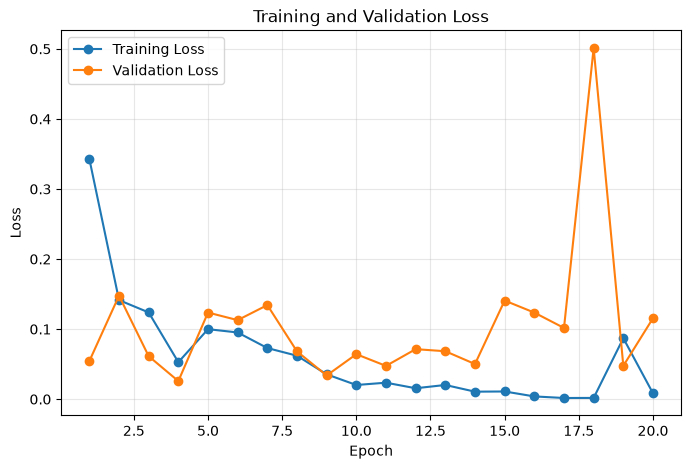

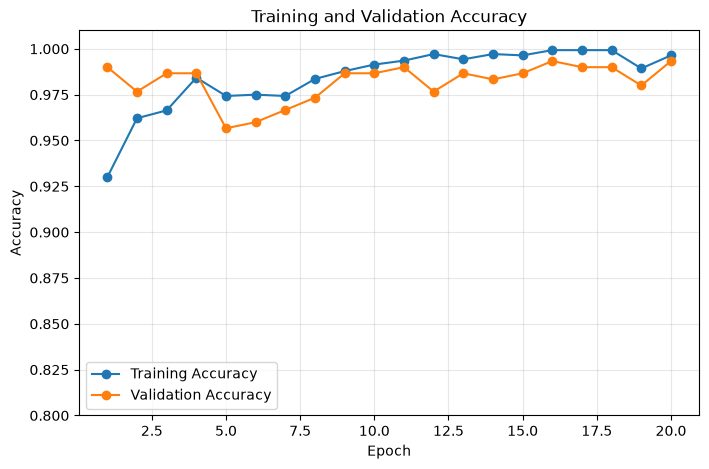

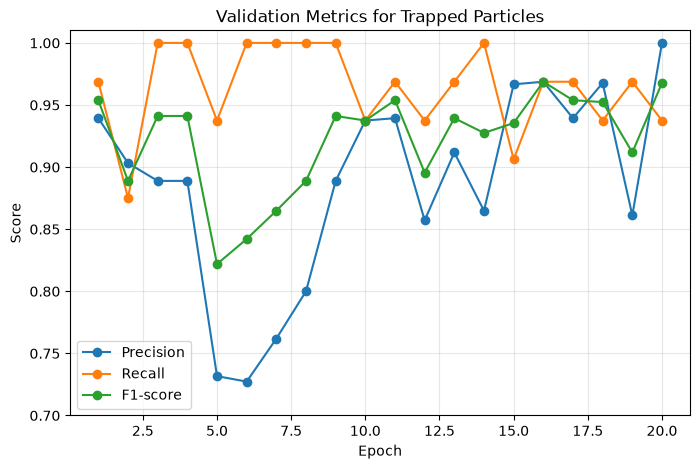

In [21]:
# ==========================================
# 5. Result visualization
# ==========================================

import matplotlib.pyplot as plt

# epoch横轴
epochs = range(1, len(history["train_loss"])+1)

# ==========================================
# Figure 1: Loss curve
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["valid_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ==========================================
# Figure 2: Accuracy curve
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["valid_acc"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.ylim(0.8, 1.01)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ==========================================
# Figure 3: Validation metrics
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["valid_precision"], marker="o", label="Precision")
plt.plot(epochs, history["valid_recall"], marker="o", label="Recall")
plt.plot(epochs, history["valid_f1"], marker="o", label="F1-score")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Metrics for Trapped Particles")
plt.ylim(0.7, 1.01)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


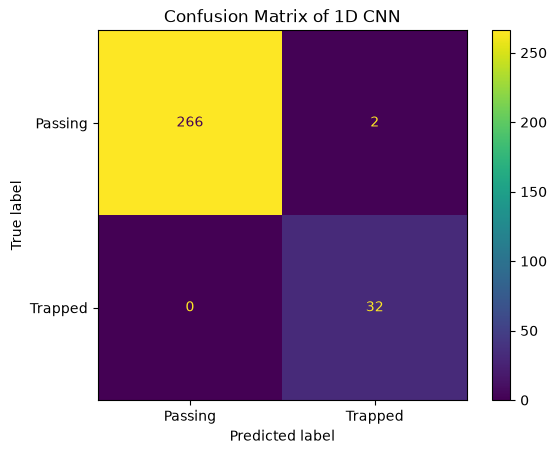

In [24]:
# ==========================================
# Figure 4: Confusion matrix
# ==========================================
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(test_true, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Passing", "Trapped"])
disp.plot(values_format="d")
plt.title("Confusion Matrix of 1D CNN")
plt.show()

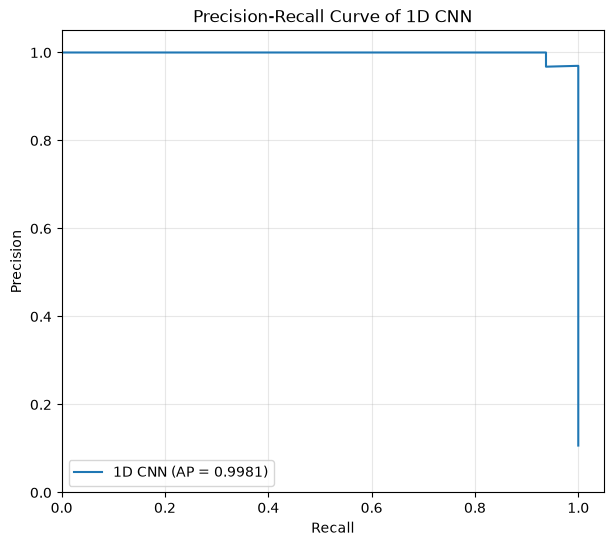

In [25]:
# ==========================================
# Figure 5: Precision-Recall curve
# ==========================================
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

precision, recall, thresholds = (precision_recall_curve(test_true, test_prob))
average_precision = average_precision_score(test_true, test_prob)
plt.figure(figsize=(7,6))
plt.plot(recall, precision, label=f"1D CNN (AP = {average_precision:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve of 1D CNN")
plt.xlim(0.0, 1.05)
plt.ylim(0.0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Test initial-condition shape = (300,)
TN = 266
TP = 32
FP = 2
FN = 0


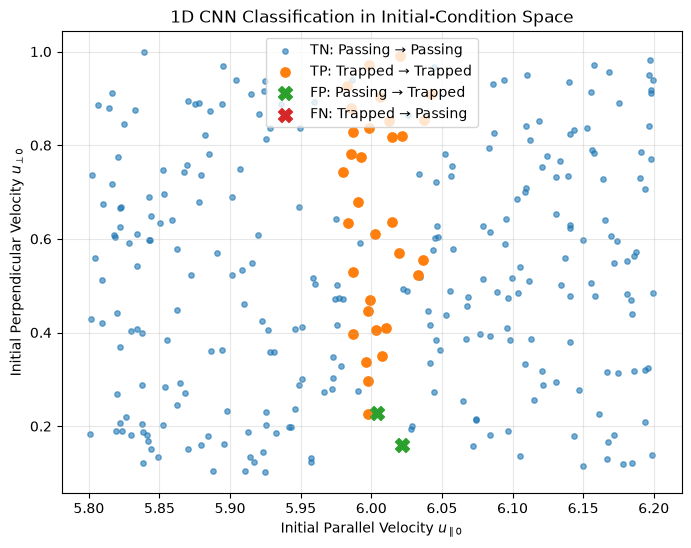

In [30]:
# ==========================================
# Figure 6: Initial-condition classification map
# ==========================================

# 1. 读取所有粒子的初始条件
u_parallel0 = data["u_parallel0"]
u_perp0 = data["u_perp0"]
psi0 = data["psi0"]

# 2. 只提取测试集粒子
u_parallel0_test = u_parallel0[test_indices]
u_perp0_test = u_perp0[test_indices]
psi0_test = psi0[test_indices]

# 3. 转换测试结果为numpy数组
test_true_array = np.array(test_true)
test_pred_array = np.array(test_pred)

print("Test initial-condition shape =", u_parallel0_test.shape)

# ==========================================
# Classification categories
# ==========================================
# True Negative:
# Passing -> Passing
tn_mask = (test_true_array == 0) & (test_pred_array == 0)
# True Positive:
# Trapped -> Trapped
tp_mask = (test_true_array == 1) & (test_pred_array == 1)
# False Positive:
# Passing -> Trapped
fp_mask = (test_true_array == 0) & (test_pred_array == 1)
# False Negative:
# Trapped -> Passing
fn_mask = (test_true_array == 1) & (test_pred_array == 0)

print("TN =", np.sum(tn_mask))
print("TP =", np.sum(tp_mask))
print("FP =", np.sum(fp_mask))
print("FN =", np.sum(fn_mask))

plt.figure(figsize=(8, 6))
# TN: 正确识别的Passing
plt.scatter(u_parallel0_test[tn_mask], u_perp0_test[tn_mask], s=15, alpha=0.6, label="TN: Passing → Passing")
# TP: 正确识别的Trapped
plt.scatter(u_parallel0_test[tp_mask], u_perp0_test[tp_mask], s=45, marker="o", label="TP: Trapped → Trapped")
# FP: 错误识别的Passing
plt.scatter(u_parallel0_test[fp_mask], u_perp0_test[fp_mask], s=100, marker="X", label="FP: Passing → Trapped")
# FN: 错误识别的Trapped
plt.scatter(u_parallel0_test[fn_mask], u_perp0_test[fn_mask], s=100, marker="X", label="FN: Trapped → Passing")

plt.xlabel(
    r"Initial Parallel Velocity $u_{\parallel 0}$"
)

plt.ylabel(
    r"Initial Perpendicular Velocity $u_{\perp 0}$"
)

plt.title(
    "1D CNN Classification in Initial-Condition Space"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

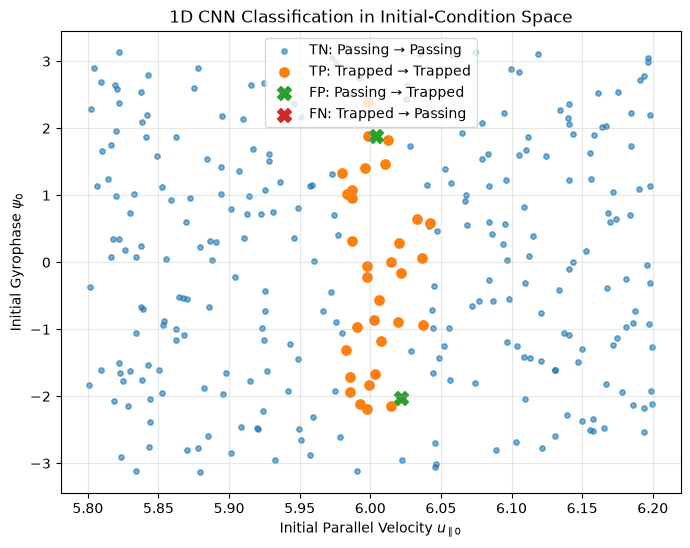

In [31]:
# ==========================================
# Figure 7: u_parallel0 - psi0 map
# ==========================================

plt.figure(figsize=(8, 6))

# TN
plt.scatter(
    u_parallel0_test[tn_mask],
    psi0_test[tn_mask],
    s=15,
    alpha=0.6,
    label="TN: Passing → Passing"
)

# TP
plt.scatter(
    u_parallel0_test[tp_mask],
    psi0_test[tp_mask],
    s=45,
    marker="o",
    label="TP: Trapped → Trapped"
)

# FP
plt.scatter(
    u_parallel0_test[fp_mask],
    psi0_test[fp_mask],
    s=100,
    marker="X",
    label="FP: Passing → Trapped"
)

# FN
plt.scatter(
    u_parallel0_test[fn_mask],
    psi0_test[fn_mask],
    s=100,
    marker="X",
    label="FN: Trapped → Passing"
)

plt.xlabel(
    r"Initial Parallel Velocity $u_{\parallel 0}$"
)

plt.ylabel(
    r"Initial Gyrophase $\psi_0$"
)

plt.title(
    "1D CNN Classification in Initial-Condition Space"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

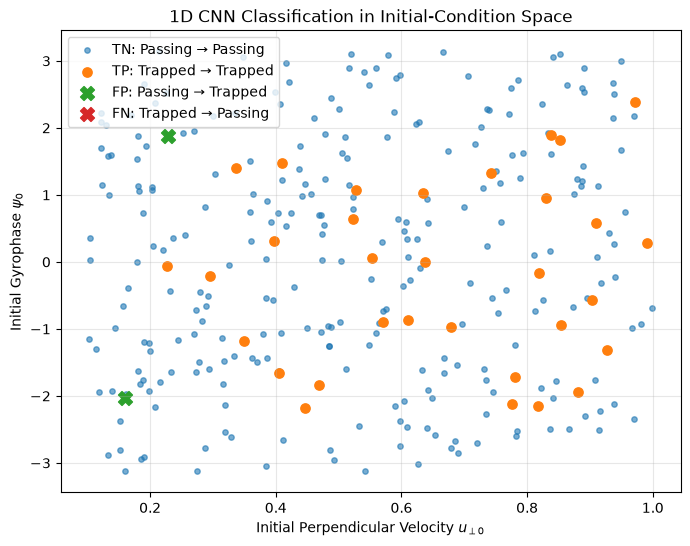

In [32]:
# ==========================================
# Figure 8: u_perp0 - psi0 map
# ==========================================

plt.figure(figsize=(8, 6))

# TN
plt.scatter(
    u_perp0_test[tn_mask],
    psi0_test[tn_mask],
    s=15,
    alpha=0.6,
    label="TN: Passing → Passing"
)

# TP
plt.scatter(
    u_perp0_test[tp_mask],
    psi0_test[tp_mask],
    s=45,
    marker="o",
    label="TP: Trapped → Trapped"
)

# FP
plt.scatter(
    u_perp0_test[fp_mask],
    psi0_test[fp_mask],
    s=100,
    marker="X",
    label="FP: Passing → Trapped"
)

# FN
plt.scatter(
    u_perp0_test[fn_mask],
    psi0_test[fn_mask],
    s=100,
    marker="X",
    label="FN: Trapped → Passing"
)

plt.xlabel(
    r"Initial Perpendicular Velocity $u_{\perp 0}$"
)

plt.ylabel(
    r"Initial Gyrophase $\psi_0$"
)

plt.title(
    "1D CNN Classification in Initial-Condition Space"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [33]:
# ==========================================
# Find false-positive particles
# ==========================================

fp_particle_indices = test_indices[fp_mask]

print("False-positive particle indices:")
print(fp_particle_indices)

print("\nInitial conditions:")

for idx in fp_particle_indices:
    print(
        f"Particle {idx}: "
        f"u_parallel0 = {u_parallel0[idx]:.4f}, "
        f"u_perp0 = {u_perp0[idx]:.4f}, "
        f"psi0 = {psi0[idx]:.4f}"
    )

False-positive particle indices:
[ 227 1969]

Initial conditions:
Particle 227: u_parallel0 = 6.0221, u_perp0 = 0.1604, psi0 = -2.0329
Particle 1969: u_parallel0 = 6.0039, u_perp0 = 0.2290, psi0 = 1.8800


Particle 227
Phase span = 5.8727 turns
Net phase change = 5.8727 turns


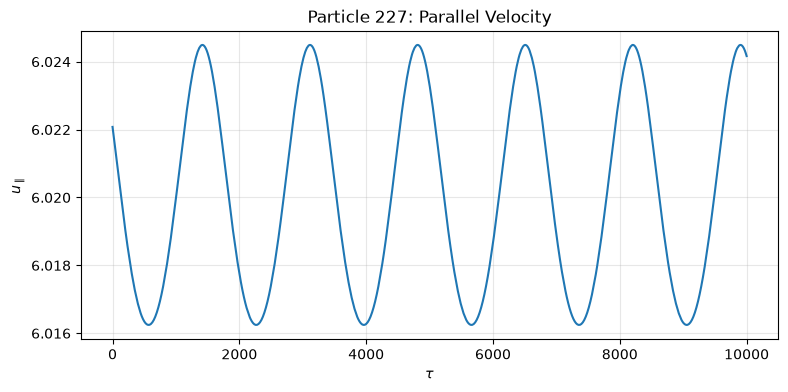

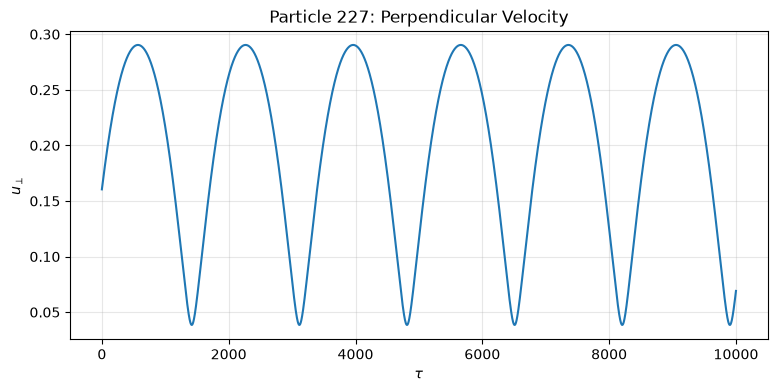

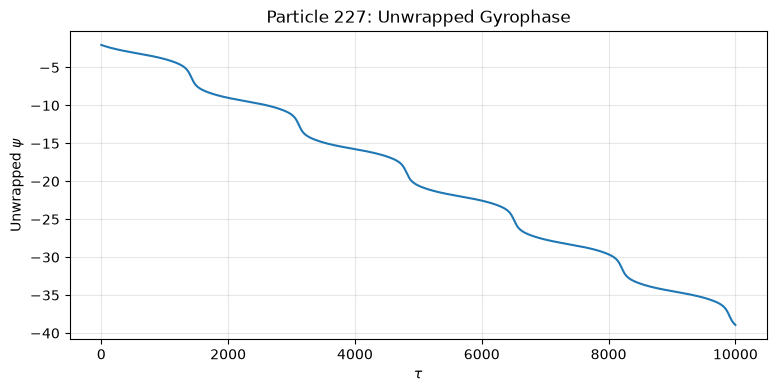

Particle 1969
Phase span = 3.8951 turns
Net phase change = 3.8661 turns


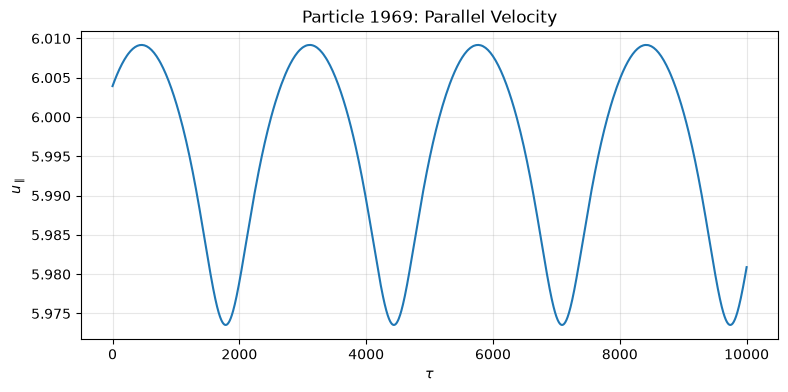

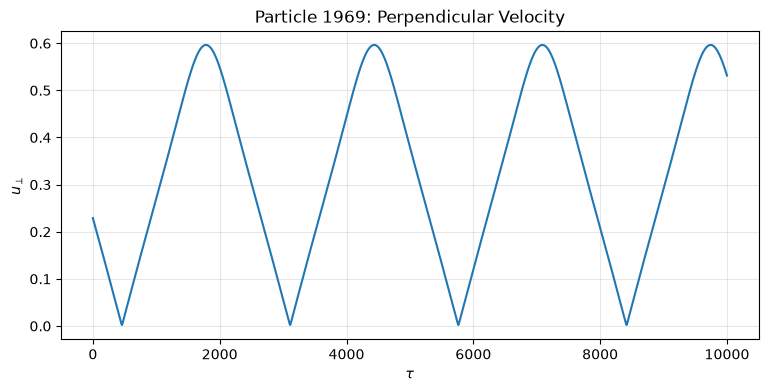

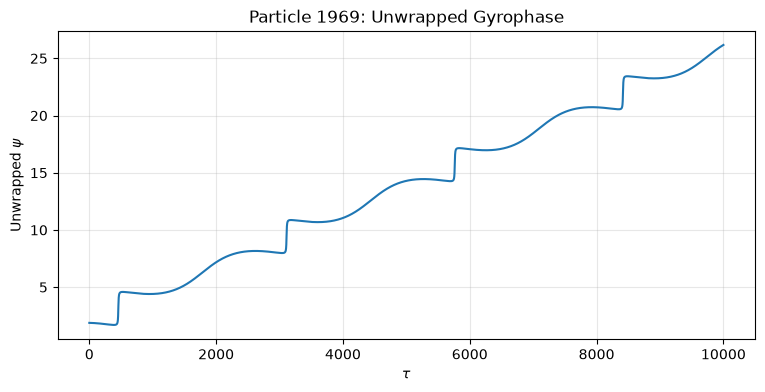

In [34]:
# ==========================================
# False-positive trajectory analysis
# ==========================================

fp_indices = [227, 1969]

# CNN使用后的时间轴
tau_cnn = np.arange(
    u_parallel.shape[0]
) * DT_CNN

for idx in fp_indices:

    # 取单个粒子的轨迹
    u_parallel_fp = u_parallel[:, idx]
    u_perp_fp = u_perp[:, idx]
    psi_fp = psi[:, idx]

    # 将psi展开，去掉 ±pi 跳变
    psi_unwrapped_fp = np.unwrap(
        psi_fp
    )

    # 计算phase span
    phase_span_turns = (
        psi_unwrapped_fp.max()
        - psi_unwrapped_fp.min()
    ) / (2 * np.pi)

    # 计算net phase change
    net_phase_turns = (
        abs(
            psi_unwrapped_fp[-1]
            - psi_unwrapped_fp[0]
        )
        / (2 * np.pi)
    )

    print(
        f"Particle {idx}"
    )

    print(
        f"Phase span = "
        f"{phase_span_turns:.4f} turns"
    )

    print(
        f"Net phase change = "
        f"{net_phase_turns:.4f} turns"
    )

    # ------------------------------
    # u_parallel
    # ------------------------------

    plt.figure(figsize=(9, 4))

    plt.plot(
        tau_cnn,
        u_parallel_fp
    )

    plt.xlabel(r"$\tau$")
    plt.ylabel(r"$u_\parallel$")

    plt.title(
        f"Particle {idx}: "
        "Parallel Velocity"
    )

    plt.grid(alpha=0.3)
    plt.show()

    # ------------------------------
    # u_perp
    # ------------------------------

    plt.figure(figsize=(9, 4))

    plt.plot(
        tau_cnn,
        u_perp_fp
    )

    plt.xlabel(r"$\tau$")
    plt.ylabel(r"$u_\perp$")

    plt.title(
        f"Particle {idx}: "
        "Perpendicular Velocity"
    )

    plt.grid(alpha=0.3)
    plt.show()

    # ------------------------------
    # unwrapped psi
    # ------------------------------

    plt.figure(figsize=(9, 4))

    plt.plot(
        tau_cnn,
        psi_unwrapped_fp
    )

    plt.xlabel(r"$\tau$")
    plt.ylabel(
        r"Unwrapped $\psi$"
    )

    plt.title(
        f"Particle {idx}: "
        "Unwrapped Gyrophase"
    )

    plt.grid(alpha=0.3)
    plt.show()